# Qdislib — 07 · Cutting a quantum image, distributed with PyCOMPSs

**A handful of qubits holds a whole image.** With QPIE (Quantum Probability
Image Encoding) an `n`-qubit state is a probability distribution over `2**n`
bitstrings — read each bitstring as a **pixel address** and its probability as
the pixel **brightness**. So **4 qubits index all 16 rows** (`2**4 = 16`), 4
more index all 16 columns, and just **8 qubits encode the whole 16×16 = 256
pixel image** — an *exponential* packing (8 qubits for 256 pixels).

That packing is exactly *why you'd cut*: an image that needs 8 qubits can be
run as **two independent 4-qubit halves** — the rows and the columns — and
reassembled. In this notebook you encode an image, **entangle** the two
registers, **cut the 8-qubit circuit into two 4-qubit pieces**, and rebuild the
full image with `gate_cutting_sampling` (which reconstructs the whole output
*distribution*, not just one number). **The whole notebook runs under
PyCOMPSs**, so the subcircuits sample in parallel.

Here's the story you'll build — encode → entangle → cut & reconstruct:

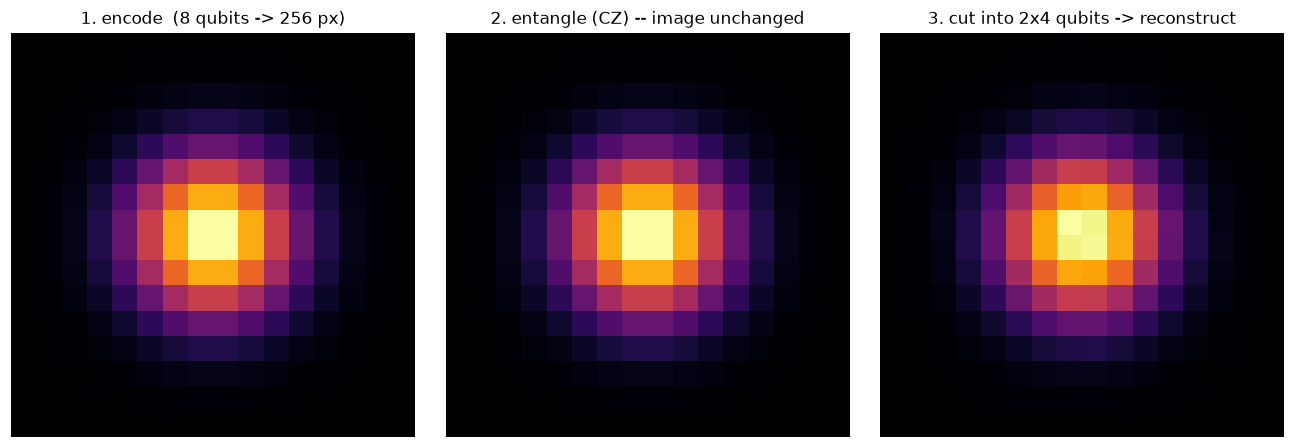

Look for the **🔧 Your turn** cells: change a line, re-run, watch it change.

## Start the PyCOMPSs runtime

This starts the COMPSs runtime **for the whole notebook**: from here on every
`gate_cutting_sampling` call submits its subcircuits as parallel COMPSs
`@task`s and gathers the results for you — the code is identical to running it
serially. `graph=True` records the task graph under `$HOME/.COMPSs/…/monitor/`
(render it with `compss_gengraph`). Run this notebook top to bottom; the very
last cell stops the runtime.

In [ ]:
import pycompss.interactive as ipycompss
ipycompss.start(graph=True, monitor=1000)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation
import qiskit.quantum_info as qi
import Qdislib as qd

N_ROW = N_COL = 4          # 4 row qubits + 4 column qubits
N = N_ROW + N_COL          # -> 16 x 16 = 256 pixels


def brightness_profile(n_bits, center, width):
    """Amplitudes whose |.|**2 form a Gaussian bump over 2**n_bits values."""
    x = np.arange(2 ** n_bits)
    p = np.exp(-0.5 * ((x - center) / width) ** 2)
    return np.sqrt(p / p.sum())


def to_image(distribution):
    """{bitstring: probability}  ->  16x16 array (row bits | column bits)."""
    image = np.zeros((2 ** N_ROW, 2 ** N_COL))
    for bitstring, prob in distribution.items():
        row = int(bitstring[:N_ROW][::-1], 2)
        col = int(bitstring[N_ROW:][::-1], 2)
        image[row, col] += prob
    return image


def show(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img, cmap='inferno'); ax.set_title(title); ax.axis('off')
    plt.show()

## 1. Encode the image  ·  *4 qubits → 16 positions*

We load a **row** brightness profile onto the 4 row qubits and a **column**
profile onto the 4 column qubits (`StatePreparation`). Each 4-qubit register
spans all `2**4 = 16` positions along its axis — so **8 qubits hold the whole
16×16 image**. Preparing the two registers independently makes a smooth,
separable blob (`row_profile ⊗ column_profile`).

In [ ]:
def encode_image(entangle, transform=None, center=7.5, profile='blob'):
    qc = QuantumCircuit(N)
    # QPIE: load a row profile and a column profile. 'blob' is the smooth
    # Gaussian bump; 'ramp' is a directional gradient -- asymmetric, so a
    # reflection visibly reverses it instead of merely relocating a symmetric blob.
    def amps(n_bits):
        if profile == 'ramp':
            p = np.arange(2 ** n_bits) + 1.0        # dark -> bright gradient
            return np.sqrt(p / p.sum())
        return brightness_profile(n_bits, center=center, width=2.2)
    qc.append(StatePreparation(amps(N_ROW)), range(N_ROW))
    qc.append(StatePreparation(amps(N_COL)), range(N_ROW, N))
    qc = transpile(qc, basis_gates=['ry', 'rz', 'cx', 'cz', 'h', 'x'],
                   optimization_level=1)
    # GEOMETRIC TRANSFORM (step 2b): an X on an address qubit flips that
    # coordinate bit; flipping every bit maps index k -> (2**n - 1) - k, a clean
    # mirror. X acts inside one register, so it never crosses the row<->column
    # cut -- the transform reconstructs faithfully from the two halves.
    if transform in ('flip_rows', 'rotate_180'):
        for q in range(N_ROW):        # mirror rows: top <-> bottom
            qc.x(q)
    if transform in ('flip_cols', 'rotate_180'):
        for q in range(N_ROW, N):     # mirror columns: left <-> right
            qc.x(q)
    if entangle:
        # ENTANGLE (step 2): couple the two registers with two CZ gates, each
        # tying a row qubit to a column qubit. These are our cut points.
        qc.cz(0, N_ROW)
        qc.cz(N_ROW - 1, N - 1)
    return qc


def exact_image(qc):
    """The true image, from the exact statevector (our ground truth)."""
    probs = np.abs(qi.Statevector(qc).data) ** 2
    dist = {''.join(str((i >> q) & 1) for q in range(N)): probs[i]
            for i in range(2 ** N)}
    return to_image(dist)


show([exact_image(encode_image(entangle=False))], ['encoded image (a blob)'])

## 2. Entangle the rows and columns

Now we couple the two registers with two `CZ` (controlled-Z) gates, each from
a **row qubit to a column qubit**. This genuinely **entangles** the 8-qubit
state — it is no longer a product of an independent row state and column
state, so you can't just run the two 4-qubit halves separately and multiply.

A `CZ` only adds a **phase**, so it leaves the measurement probabilities — the
**image** — exactly unchanged. That's the point of this demo: the picture
stays put while the circuit becomes entangled, so when we cut and rebuild it,
a correct reconstruction must return the **identical** blob. (These two `CZ`
gates are the cut points in step 3.)

In [ ]:
show([exact_image(encode_image(entangle=False)),
      exact_image(encode_image(entangle=True))],
     ['before (separable)', 'after CZ (entangled -- image unchanged)'])

### 🔧 Your turn (1)

Change the **blob**: move its center or make it wider/narrower, then re-run.
Try `center=4.0` (top-left) or `width=1.0` (sharper).

In [ ]:
def brightness_profile(n_bits, center, width):        # <-- edit center / width
    x = np.arange(2 ** n_bits)
    p = np.exp(-0.5 * ((x - center) / width) ** 2)
    return np.sqrt(p / p.sum())

show([exact_image(encode_image(entangle=True))], ['your image'])

## 2b. A geometric transform that survives the cut

The `CZ` left the image untouched — a pure fidelity check. But we can also
**transform** the image with gates and watch the transform come back through
the cut. The clean transforms in QPIE are the **geometric** ones: an `X` on an
address qubit flips that coordinate bit, and flipping *every* bit of a
coordinate maps index `k → (2**n − 1) − k` — a **mirror reflection**. Each `X`
acts inside a single register, so it never crosses the row↔column cut: the
reflected image is reconstructed from the two halves just as faithfully. (We
switch to a directional **gradient** here — a mirror of the *symmetric* blob
would only relocate it, so you'd never actually see the flip.)

*(Why reflect and not shrink/zoom? Scaling a QPIE image is a **resampling** —
shrinking is 2-to-1 (non-unitary) and zooming needs an extra qubit — so it is
not a clean gate. The easy way to resize the blob is at encode time, via
`width`. Reflections, translations and 90° rotations are the clean ones.)*

In [ ]:
# A directional gradient makes the reflection unmistakable -- the bright side
# reverses. (A symmetric blob would just relocate, so the flip would be
# invisible.) transform: 'flip_rows', 'flip_cols' or 'rotate_180' (both axes).
ramp = dict(entangle=False, profile='ramp')
show([exact_image(encode_image(**ramp)),
      exact_image(encode_image(**ramp, transform='flip_rows')),
      exact_image(encode_image(**ramp, transform='flip_cols')),
      exact_image(encode_image(**ramp, transform='rotate_180'))],
     ['original (gradient)', 'flip rows', 'flip cols', 'rotate 180°'])

### 🔧 Your turn (1b)

**Cut and reconstruct a transformed image.** Pick a `TRANSFORM` and re-run: the
reconstruction from the two 4-qubit halves matches the *transformed* image, not
the original — the transform rode through the cut.

In [ ]:
TRANSFORM = 'flip_cols'      # <-- 'flip_rows' / 'flip_cols' / 'rotate_180' / None

moved = encode_image(entangle=True, profile='ramp', transform=TRANSFORM)
cut_moved = qd.find_cut(moved, gate_cut=True, wire_cut=False, max_qubits=N_ROW)
dist_moved = qd.gate_cutting_sampling(moved, cut_moved, shots=200_000,
                                      software='qiskit')
show([exact_image(moved), to_image(dist_moved)],
     ['transformed image (exact)', 'reconstructed from the 2 halves'])

## 3. The image is an 8-qubit circuit — cut it in two

Suppose our device only has ~4 qubits. `find_cut` looks for a good place to
split the circuit; here it finds the two row↔column `CZ` gates, which separate
the **row half** from the **column half**.

In [ ]:
entangled = encode_image(entangle=True)
cut = qd.find_cut(entangled, gate_cut=True, wire_cut=False, max_qubits=N_ROW)
print('cut gates:', cut)   # the two row<->column entanglers

### The circuit we're cutting

Here is the actual **transpiled** 8-qubit circuit `find_cut` worked on. Each
`StatePreparation` has compiled down to `ry` / `rz` / `cx` **inside its
register**, and the only gates joining the row register (`q0–q3`) to the
column register (`q4–q7`) are the two `CZ` — the cut points. It is a concrete
gate list, not an opaque block, which is exactly what lets it be cut.

In [ ]:
print('gate counts:', dict(entangled.count_ops()), '| depth:', entangled.depth())
# Text drawing (no extra deps). The two CZ (q0-q4 and q3-q7) are the only gates
# spanning the row and column registers -- the cut points.
print(entangled.draw(fold=74))

## 4. Reconstruct the image by sampling the pieces — in parallel

We use the **three-step workflow**, which exposes each piece (so you can
inspect, batch, cache or place them individually):

1. `gate_cutting_sampling_subcircuits` splits the cut into the sampling
   subcircuits — two cuts ⇒ `6**2 = 36` configurations, each a small 4-qubit
   circuit;
2. `sample_subcircuit` samples one subcircuit — **under PyCOMPSs each call is a
   COMPSs task**, so the pieces sample in parallel (and you decide where each
   one runs — e.g. a QPU, step 5);
3. `subs.reconstruct(...)` recombines them (via the gate-cut quasiprobability
   decomposition) into the **full output distribution** — the reconstructed
   image.

The one-liner `gate_cutting_sampling(entangled, cut, ...)` just wraps these
three steps.

In [ ]:
subs = qd.gate_cutting_sampling_subcircuits(entangled, cut, software='qiskit')
print(len(subs), 'sampling subcircuits (6**2 configs x components)')

# Each sample_subcircuit call is a COMPSs task -> the pieces sample in parallel.
sampled = [qd.sample_subcircuit(s, shots=200_000) for s in subs]
distribution = subs.reconstruct(sampled)
reconstructed = to_image(distribution)

show([exact_image(entangled), reconstructed],
     ['exact image', 'reconstructed from the 2 halves'])

tvd = 0.5 * np.abs(exact_image(entangled) - reconstructed).sum()
print(f'total-variation distance vs exact: {tvd:.4f}   (~shot noise)')

### 🔧 Your turn (2)

Fewer shots ⇒ a noisier reconstruction. Re-run with `shots=20_000` and compare
the image and the TVD. (Sampling reconstruction carries a quasiprobability
overhead, so it needs more shots than a plain expectation value.)

In [ ]:
distribution = qd.gate_cutting_sampling(entangled, cut, shots=20_000,   # <-- change
                                        software='qiskit')
noisy = to_image(distribution)
show([reconstructed, noisy], ['200k shots', '20k shots'])
print('TVD:', round(0.5 * np.abs(exact_image(entangled) - noisy).sum(), 4))

## 5. Send the pieces to a real BSC quantum computer

The subcircuits are only **4 qubits** — small enough for today's hardware. To
sample them on a **real BSC QPU** instead of the local simulator, pass
`qpu=True` and name the machine with `qpu_dict` (QPU → its qubit count). The
call is otherwise identical: Qdislib ships each subcircuit to the QPU, gathers
the counts, and rebuilds the image for you. (This needs access to the BSC
quantum environment, so it isn't run in this docs build.)

In [ ]:
distribution = qd.gate_cutting_sampling(
    entangled, cut, shots=4096,
    software='qibo', qpu=True, qpu_dict={'MN_Ona': N_ROW},
)
show([exact_image(entangled), to_image(distribution)],
     ['exact image', 'reconstructed on a BSC QPU'])

### What a real (noisy) run looks like

On hardware the reconstruction still recovers the blob, but gate and readout
errors blur it and add a background haze — and cutting's quasiprobability
overhead amplifies shot noise, so hardware runs want **more shots** and **error
mitigation**. Here is the same image reconstructed on an ideal simulator versus
a noisy QPU run:

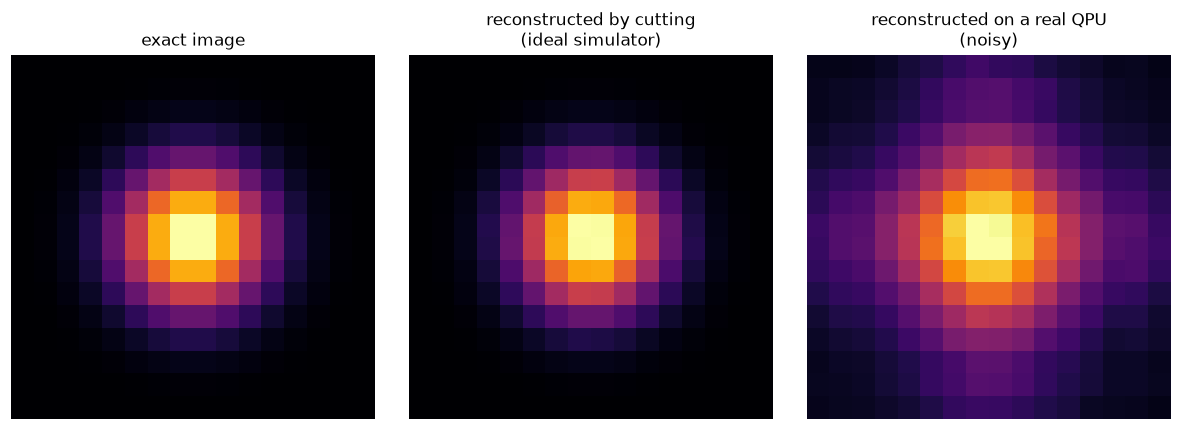

## Recap & bonus

You encoded a 256-pixel image in **8 qubits**, entangled the row and column
registers with `CZ`, **cut the 8-qubit circuit into two 4-qubit halves**, and
rebuilt the *full image distribution* by sampling — all running distributed
under PyCOMPSs — recovering the identical blob.

**🔧 Bonus:** bump the resolution to `32×32` with `N_ROW = N_COL = 5` (re-run
from the setup cell). The circuit grows to 10 qubits and each half to 5 — but
it's still just **two cuts** (the cost scales with the number of cuts,
`6**n_cuts`, not the circuit size).

## Stop the PyCOMPSs runtime

Run this **last**, once you're done re-running the cells above — it shuts the
COMPSs runtime down cleanly, syncing any outstanding results.

In [ ]:
ipycompss.stop(sync=True)